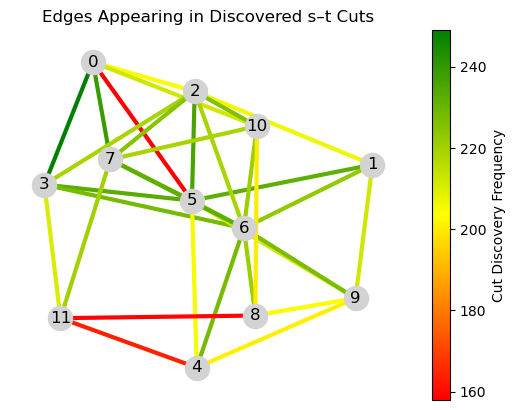

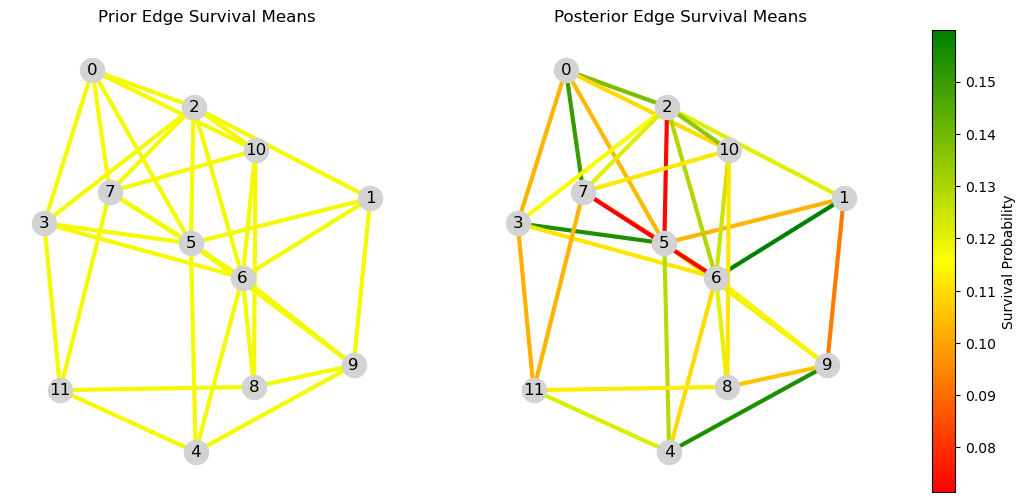

In [44]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

np.random.seed(42)

# ============================================================
# 1. Build Well-Connected Graph
# ============================================================

n = 12
p_connect = 0.5

G = nx.erdos_renyi_graph(n, p_connect)
while not nx.is_connected(G):
    G = nx.erdos_renyi_graph(n, p_connect)

s, t = 0, n - 1
edges = [tuple(sorted(e)) for e in G.edges()]

# ============================================================
# 2. Prior Beta parameters
# ============================================================

alpha0 = 2
beta0 = 15

alpha_post = {e: alpha0 for e in edges}
beta_post  = {e: beta0  for e in edges}

discovered_cuts = []
levels = [0.25, 0.5, 0.75, 1.0]

# ============================================================
# 3. Adaptive Splitting Monte Carlo (Functional)
# ============================================================

def adaptive_splitting_mc(G, edges, alpha_init, beta_init, discovered_cuts_init, levels,
                          N=1000, split_factor=2):
    """
    Functional adaptive splitting MC with resampling at each split.
    Returns posterior alpha/beta, discovered cuts, and edge cut counts.
    """
    alpha_post = alpha_init.copy()
    beta_post = beta_init.copy()
    discovered_cuts = list(discovered_cuts_init)
    num_edges = len(edges)

    # Utilities
    def sample_edge_probs():
        return np.array([np.random.beta(alpha_post[e], beta_post[e]) for e in edges])

    def extract_cut_from_mask(mask):
        failed_edges = {edges[i] for i, f in enumerate(mask) if f}
        H = G.copy()
        H.remove_edges_from(failed_edges)
        if nx.has_path(H, s, t):
            return None
        S = nx.node_connected_component(H, s)
        T = set(G.nodes()) - S
        cut = frozenset(tuple(sorted(edge)) for edge in nx.edge_boundary(G, S, T))
        return cut

    def progress_metric_mask(mask):
        failed_edges = {edges[i] for i, f in enumerate(mask) if f}
        if not discovered_cuts:
            # Bootstrap: fraction of edges failed
            return len(failed_edges) / num_edges
        # Max overlap with discovered cuts
        return max(len(set(cut) & failed_edges)/len(cut) for cut in discovered_cuts)

    # ----------------- Simulation Loop -----------------
    for _ in range(N):
        edge_probs = sample_edge_probs()
        # Initial particle
        particles = [(np.random.rand(num_edges) > edge_probs, 1.0)]

        for threshold in levels:
            survivors = []
            for mask, weight in particles:
                phi = progress_metric_mask(mask)
                if phi >= threshold:
                    survivors.append((mask, weight))
            if not survivors:
                particles = []
                break

            # Split survivors with **resampling for variability**
            new_particles = []
            for mask, weight in survivors:
                for _ in range(split_factor):
                    # Resample edges independently based on edge_probs
                    new_mask = np.random.rand(num_edges) > edge_probs
                    new_particles.append((new_mask, weight / split_factor))
            particles = new_particles

        # ----------------- Posterior Update -----------------
        for mask, weight in particles:
            cut = extract_cut_from_mask(mask)
            if cut is not None and cut not in discovered_cuts:
                discovered_cuts.append(cut)
            for i, e in enumerate(edges):
                if mask[i]:
                    beta_post[e] += weight
                else:
                    alpha_post[e] += weight

    # ----------------- Compute cut counts -----------------
    cut_counts = {e: 0 for e in edges}
    for cut in discovered_cuts:
        for e in cut:
            cut_counts[e] += 1

    return alpha_post, beta_post, discovered_cuts, cut_counts

# ============================================================
# 4. Run Simulation
# ============================================================

alpha_post, beta_post, discovered_cuts, cut_counts = adaptive_splitting_mc(
    G, edges, alpha_post, beta_post, discovered_cuts, levels,
    N=1000, split_factor=2
)

# ============================================================
# 5. Plot Cut Discovery Frequency
# ============================================================

values = np.array(list(cut_counts.values()))
vmin, vmax = values.min(), values.max()

colors = ['red', 'yellow', 'green']
cmap = mcolors.LinearSegmentedColormap.from_list("custom_red_yellow_green", colors)
norm = plt.Normalize(vmin=vmin, vmax=vmax)

edge_colors = [cmap(norm(cut_counts[e])) for e in edges]

fig, ax = plt.subplots()
pos = nx.spring_layout(G, seed=2)

nx.draw_networkx_nodes(G, pos, node_color="lightgray", ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=edges, edge_color=edge_colors, width=3, ax=ax)
nx.draw_networkx_labels(G, pos, ax=ax)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array(values)
fig.colorbar(sm, ax=ax, label="Cut Discovery Frequency")

ax.set_title("Edges Appearing in Discovered s–t Cuts")
ax.set_axis_off()
plt.show()

# ============================================================
# 6. Side-by-Side Prior vs Posterior Plot
# ============================================================

def plot_prior_posterior(G, edges, alpha0, beta0, alpha_post, beta_post, cmap):
    prior_means = {e: alpha0 / (alpha0 + beta0) for e in edges}
    posterior_means = {e: alpha_post[e] / (alpha_post[e] + beta_post[e]) for e in edges}

    all_vals = list(prior_means.values()) + list(posterior_means.values())
    norm = plt.Normalize(vmin=min(all_vals), vmax=max(all_vals))

    prior_colors = [cmap(norm(prior_means[e])) for e in edges]
    posterior_colors = [cmap(norm(posterior_means[e])) for e in edges]

    fig, axes = plt.subplots(1, 2, figsize=(14,6))
    pos = nx.spring_layout(G, seed=2)

    # PRIOR
    nx.draw_networkx_nodes(G, pos, node_color="lightgray", ax=axes[0])
    nx.draw_networkx_edges(G, pos, edgelist=edges, edge_color=prior_colors, width=3, ax=axes[0])
    nx.draw_networkx_labels(G, pos, ax=axes[0])
    axes[0].set_title("Prior Edge Survival Means")
    axes[0].set_axis_off()

    # POSTERIOR
    nx.draw_networkx_nodes(G, pos, node_color="lightgray", ax=axes[1])
    nx.draw_networkx_edges(G, pos, edgelist=edges, edge_color=posterior_colors, width=3, ax=axes[1])
    nx.draw_networkx_labels(G, pos, ax=axes[1])
    axes[1].set_title("Posterior Edge Survival Means")
    axes[1].set_axis_off()

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array(all_vals)
    fig.colorbar(sm, ax=axes.ravel().tolist(), label="Survival Probability")
    plt.show()
    return prior_means, posterior_means

colors = ['red', 'yellow', 'green']
cmap = mcolors.LinearSegmentedColormap.from_list("custom_red_yellow_green", colors)
prior_means, posterior_means = plot_prior_posterior(G, edges, alpha0, beta0, alpha_post, beta_post, cmap)

In [29]:
alpha_post

{(0, 1): 2,
 (0, 2): 2,
 (0, 4): 2,
 (0, 6): 2,
 (0, 7): 2,
 (0, 9): 2,
 (0, 11): 2,
 (1, 2): 2,
 (1, 4): 2,
 (1, 6): 2,
 (1, 7): 2,
 (1, 8): 2,
 (2, 3): 2,
 (2, 6): 2,
 (2, 7): 2,
 (2, 8): 2,
 (3, 6): 2,
 (3, 7): 2,
 (3, 8): 2,
 (3, 9): 2,
 (4, 5): 2,
 (4, 7): 2,
 (4, 9): 2,
 (4, 11): 2,
 (5, 6): 2,
 (5, 9): 2,
 (6, 9): 2,
 (6, 10): 2,
 (7, 9): 2,
 (8, 11): 2}

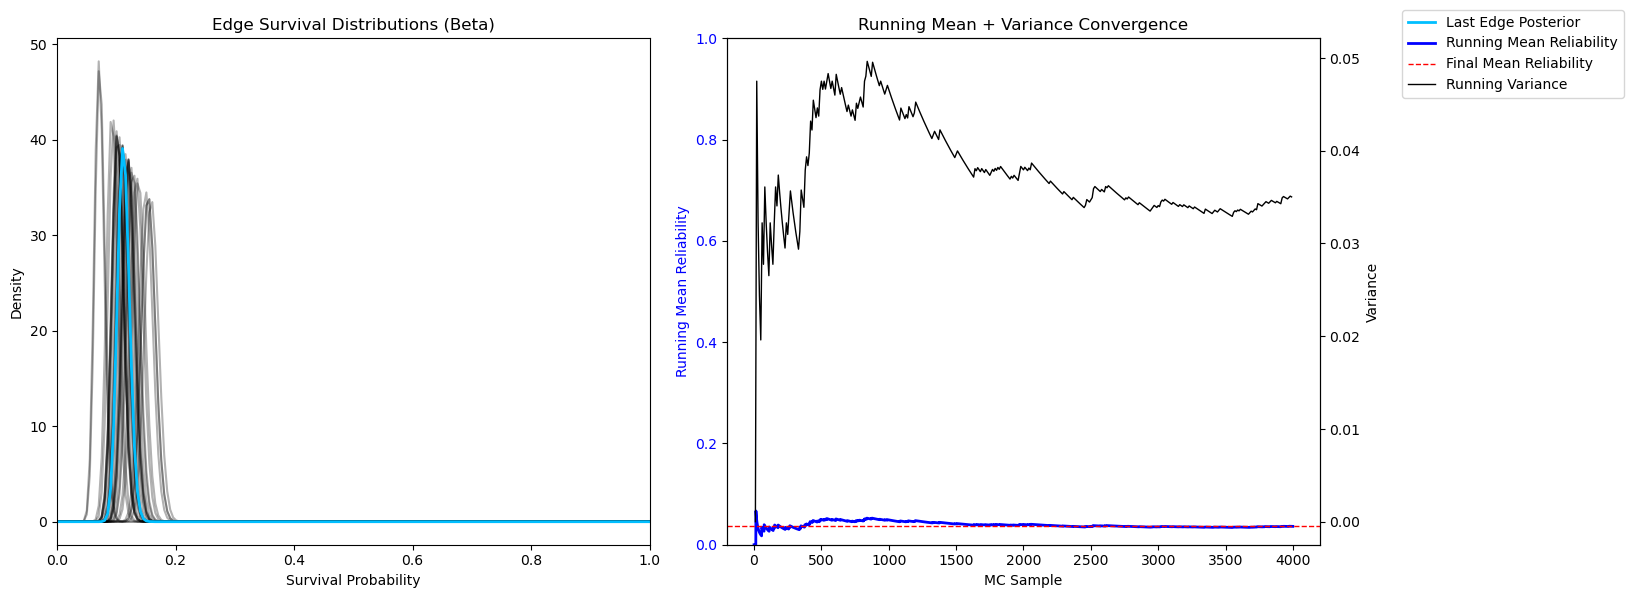

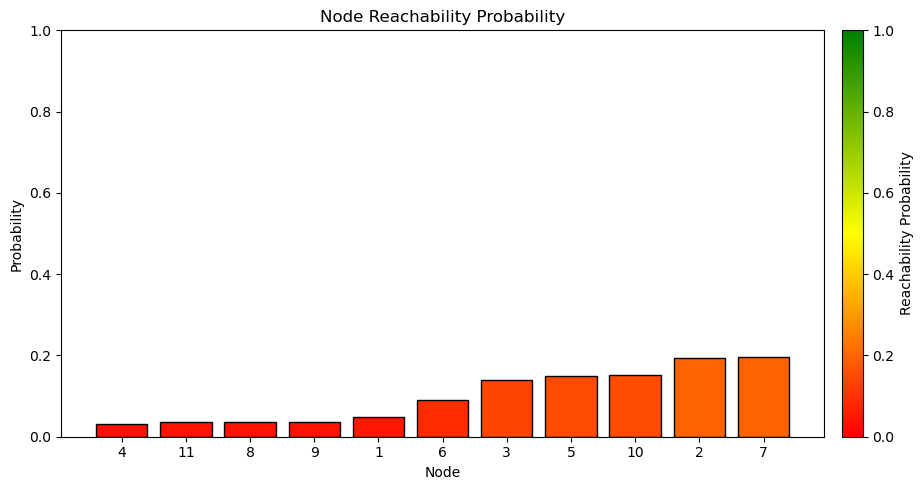

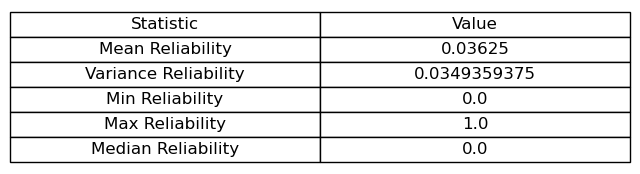

In [101]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import beta
import matplotlib.colors as mcolors
import pandas as pd

# -----------------------------
# Utilities
# -----------------------------
def running_mean(arr):
    return np.cumsum(arr) / np.arange(1, len(arr)+1)

# Custom color map for node probabilities
ryg_cmap = mcolors.LinearSegmentedColormap.from_list("RdYlGn", ["red","yellow","green"])

# -----------------------------
# Dashboard function
# -----------------------------
def reliability_dashboard_beta(G, edges, alpha_post, beta_post, s, t, M=4000):
    # Posterior means
    posterior_means = {e: alpha_post[e] / (alpha_post[e] + beta_post[e]) for e in edges}
    
    # Monte Carlo connectivity + node reachability
    connectivity = np.zeros(M)
    node_reach = {node: 0 for node in G.nodes() if node != s}

    for i in range(M):
        edge_probs = {e: np.random.beta(alpha_post[e], beta_post[e]) for e in edges}
        failed_edges = {e for e in edges if np.random.rand() > edge_probs[e]}
        H = G.copy()
        H.remove_edges_from(failed_edges)
        connectivity[i] = int(nx.has_path(H, s, t))
        reachable_nodes = nx.node_connected_component(H, s)
        for node in reachable_nodes:
            if node != s:
                node_reach[node] += 1

    node_probs = {node: cnt / M for node, cnt in node_reach.items()}
    mean_rel = connectivity.mean()
    var_rel = connectivity.var()
    run_mean = running_mean(connectivity)
    run_var = [connectivity[:i].var() for i in range(10, M, 10)]

    # -----------------------------
    # 2x1 Plot: (1) Edge survival, (2) Running mean + variance
    # -----------------------------
    fig, axes = plt.subplots(1, 2, figsize=(14,6))

    # --- Plot 1: Edge survival distributions ---
    ax0 = axes[0]
    x_vals = np.linspace(0, 1, 200)

    # Plot all edges except last in black
    for e in edges[:-1]:
        y = beta.pdf(x_vals, alpha_post[e], beta_post[e])
        ax0.plot(x_vals, y, color='black', alpha=0.3, label='_nolegend_')  # suppress legend

    # Last edge posterior in light blue
    last_edge = edges[-1]
    ax0.plot(x_vals, beta.pdf(x_vals, alpha_post[last_edge], beta_post[last_edge]),
            color='deepskyblue', lw=2, label='Last Edge Posterior')

    ax0.set_title("Edge Survival Distributions (Beta)")
    ax0.set_xlabel("Survival Probability")
    ax0.set_ylabel("Density")
    ax0.set_xlim(0,1)

    # --- Plot 2: Running mean + variance convergence ---
    ax_mean = axes[1]
    ax_var = ax_mean.twinx()

    # Running mean in blue
    ax_mean.plot(run_mean, color="blue", lw=2, label="Running Mean Reliability")
    # Final mean as dashed red line
    ax_mean.axhline(mean_rel, color="red", linestyle="--", lw=1, label="Final Mean Reliability")
    # Running variance in black
    ax_var.plot(np.arange(10, M, 10), run_var, color="black", lw=1, label="Running Variance")

    ax_mean.set_ylim(0,1)
    ax_mean.set_xlabel("MC Sample")
    ax_mean.set_ylabel("Running Mean Reliability", color="blue")
    ax_mean.tick_params(axis='y', labelcolor="blue")
    ax_var.set_ylabel("Variance", color="black")
    ax_var.tick_params(axis='y', labelcolor="black")

    ax_mean.set_title("Running Mean + Variance Convergence")

    # -----------------------------
    # Combined legend outside figure
    # -----------------------------
    lines_labels = [ax.get_legend_handles_labels() for ax in [ax0, ax_mean, ax_var]]
    lines, labels = [sum(lol, []) for lol in zip(*lines_labels)]
    fig.legend(lines, labels, loc='upper left', bbox_to_anchor=(1, 1), ncol=1, frameon=True)

    plt.tight_layout()
    plt.show()

    # -----------------------------
    # 3. Node reachability bar chart
    # -----------------------------
    # Filter out the source node
    node_probs_filtered = {n: p for n, p in node_probs.items() if n != s}

    # Sort nodes by probability ascending (left-to-right)
    sorted_nodes = sorted(node_probs_filtered.items(), key=lambda x: x[1])
    nodes, probs = zip(*sorted_nodes)

    # Convert to list for plotting
    nodes = list(nodes)
    probs = list(probs)

    # Normalize probabilities for color mapping
    norm = mcolors.Normalize(vmin=0, vmax=1)
    colors = [ryg_cmap(norm(p)) for p in probs]

    # x positions for bars
    x_pos = np.arange(len(nodes))

    # Create figure
    fig_nodes, ax_nodes = plt.subplots(figsize=(10,5))
    ax_nodes.bar(x_pos, probs, color=colors, edgecolor='k')

    # Set x-ticks to node labels
    ax_nodes.set_xticks(x_pos)
    ax_nodes.set_xticklabels(nodes)

    # Labels and title
    ax_nodes.set_ylim(0,1)
    ax_nodes.set_xlabel("Node")
    ax_nodes.set_ylabel("Probability")
    ax_nodes.set_title("Node Reachability Probability")

    # Add colorbar
    from matplotlib.cm import ScalarMappable
    sm = ScalarMappable(cmap=ryg_cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax_nodes, pad=0.02)
    cbar.set_label("Reachability Probability")

    plt.tight_layout()
    plt.show()

    # -----------------------------
    # 4. Statistics table
    # -----------------------------
    stats_df = pd.DataFrame({
        "Statistic": ["Mean Reliability", "Variance Reliability", "Min Reliability",
                      "Max Reliability", "Median Reliability"],
        "Value": [mean_rel, var_rel, connectivity.min(), connectivity.max(), np.median(connectivity)]
    })
    fig_table, ax_table = plt.subplots(figsize=(8,2))
    ax_table.axis('off')
    table = ax_table.table(cellText=stats_df.values,
                           colLabels=stats_df.columns,
                           cellLoc='center',
                           loc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1,1.5)

    plt.show()

    return {
        "mean_reliability": mean_rel,
        "variance": var_rel,
        "node_probs": node_probs,
        "running_mean": run_mean,
        "running_var": run_var
    }

# -----------------------------
# Example call
# -----------------------------
dashboard = reliability_dashboard_beta(
    G=G,
    edges=edges,
    alpha_post=alpha_post,
    beta_post=beta_post,
    s=0,
    t=n-1,
    M=4000
)